# Notebook 25 — Calibrating additive recurrence against ESCM 2.0

## Research question

Can **additive autaptic transmission with a 1 ms absolute refractory period** reproduce the spatial persistence, competition, and fading of our approved ESCM, without changing the neural architecture?

The reference validation was established in **Notebook 18** (unlabelled spatial competition), **Notebook 19** (five held-out geometries, 16 event-timing challenges, timestep refinement), and **Notebook 20** (the selected inhibitory radius of **5.5 pixels**, giving **3/5** strict geometry successes). These notebooks used **refreshed self-excitation without sensory support**, so their persistence criterion sampled relatively late in the simulation.

The later approved **real-event-camera/video** model added **sensory-dependent fading**: camera events set a support trace to 1, and the refreshed current is multiplied by that decaying trace. It can no longer be evaluated fairly using the old late windows. We retain **both reference definitions**, rather than calling their different dynamics identical:

| Reference | Self-excitation at output spike | Sensory support | Evaluation windows |
|---|---|---|---|
| **ESCM 2.0 (Notebook 20)** | `Iexc = 8` | No | [90,105), [105,120) ms |
| **ESCM 2.0 + fading (approved video model)** | `Iexc = 8*support` | Yes, τ = 120 ms | [32,42), [42,52) ms |

**Default target:** `fading`, because that is the latest version you approved visually. Set `target = "original"` below to calibrate against the exact Notebook 20 dynamics and late-window tests.

For each target, we preserve its camera input, inhibition, geometry definitions, and evaluation protocol. The **candidate** changes only the autapse to `Iexc += W*support` (or `Iexc += W` when the target has no support), adds a 1 ms refractory period, and permits a controlled multiplier of inhibitory strength. No STD, STF, adaptation, or extra neuronal populations are introduced.

**Finite claim tested:** agreement on five predefined five-pixel shape pairs and on the predefined event timings. Passing is not a claim of equivalence on all event streams or real video.

## 1. Network and fixed test geometries

Each pixel is a conventional LIF neuron. The network is **unlabelled**: recurrent synapses depend only on physical distance, never on which pixels happen to belong to the old or new shape.

\[
\tau_m\dot v_i=-v_i+I_{\mathrm{ext},i}+I_{\mathrm{exc},i}-I_{\mathrm{inh},i},\qquad
\tau_x\dot I_{x,i}=-I_{x,i}.
\]

Parameters are those frozen in Notebook 20: τₘ = 10 ms, τₑₓₜ = 3 ms, τₑₓ꜀ = 5 ms, τᵢₙₕ = 12 ms, threshold = 1, external increment = 22, and inhibition

\[
w_{ji}^{I}=0.1\exp\left(-\frac{d_{ij}^2}{2(2.5)^2}\right)\mathbf 1\{1.5<d_{ij}\le5.5\}.
\]

The inhibitory multiplier is a **candidate calibration parameter**, not a change to the reference. Membrane and currents continue evolving during refractoriness (Brian2's default, without `unless refractory`). Simulation step: **0.05 ms**.

/home/bmaacaron-iit.local/.virtualenvs/event-scm/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


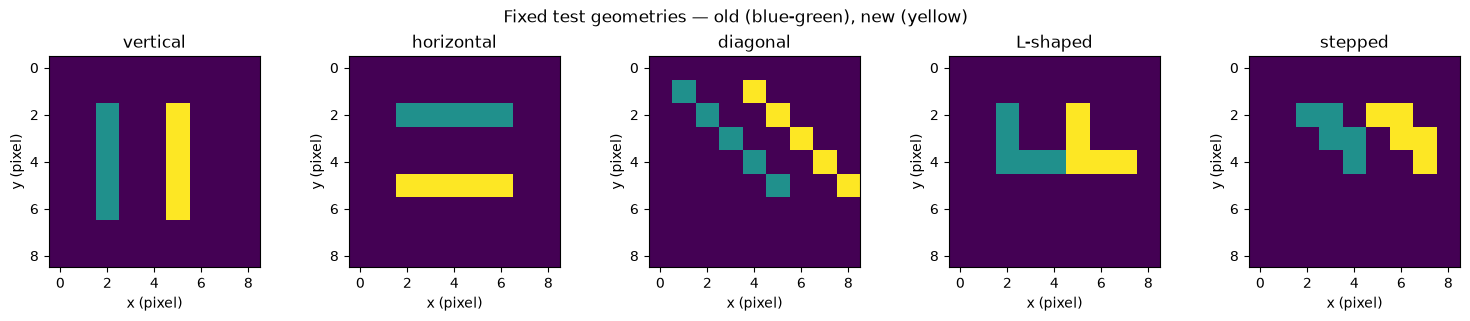

81 LIF neurons; 3620 directed inhibitory connections; target: fading


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
import brian2 as b2

b2.prefs.codegen.target = "numpy"  # Many short simulations: avoid repeated C++ compilation.

# Select which approved behavior to reproduce.
target = "fading"  # "fading" (latest approved video model) or "original" (Notebook 20)
assert target in ("fading", "original")

width = height = 9
n = width * height
xy = np.column_stack((np.arange(n) % width, np.arange(n) // width))
dt_ms = 0.05

def pixels(coords):
    return np.array([y * width + x for x, y in coords], dtype=int)

# Exact geometry definitions from Notebook 19 / 20.
shapes = {
    "vertical": (pixels([(2, y) for y in range(2, 7)]),
                 pixels([(5, y) for y in range(2, 7)])),
    "horizontal": (pixels([(x, 2) for x in range(2, 7)]),
                   pixels([(x, 5) for x in range(2, 7)])),
    "diagonal": (pixels([(x, x) for x in range(1, 6)]),
                 pixels([(x + 3, x) for x in range(1, 6)])),
    "L-shaped": (pixels([(2, 2), (2, 3), (2, 4), (3, 4), (4, 4)]),
                 pixels([(5, 2), (5, 3), (5, 4), (6, 4), (7, 4)])),
    "stepped": (pixels([(2, 2), (3, 2), (3, 3), (4, 3), (4, 4)]),
                pixels([(5, 2), (6, 2), (6, 3), (7, 3), (7, 4)])),
}

# Reused, homogeneous surround graph (same for both models and all input shapes).
distance = np.linalg.norm(xy[:, None, :] - xy[None, :, :], axis=-1)
post, pre = np.where((distance > 1.5) & (distance <= 5.5))
base_inhibition = 0.1 * np.exp(-distance[post, pre]**2 / (2 * 2.5**2))
assert all(len(a) == len(b) == 5 and len(set(a) | set(b)) == 10
           for a, b in shapes.values())

fig, axes = plt.subplots(1, 5, figsize=(15, 3.1), constrained_layout=True)
for ax, (name, (old, new)) in zip(axes, shapes.items()):
    image = np.zeros(n, dtype=int)
    image[old], image[new] = 1, 2
    ax.imshow(image.reshape(height, width), cmap="viridis", vmin=0, vmax=2,
              interpolation="nearest")
    ax.set(title=name, xlabel="x (pixel)", ylabel="y (pixel)",
           xticks=range(0, 9, 2), yticks=range(0, 9, 2))
fig.suptitle("Fixed test geometries — old (blue-green), new (yellow)")
plt.show()
print(f"{n} LIF neurons; {len(pre)} directed inhibitory connections; target: {target}")

## 2. Implement the reference and candidate with identical spatial connectivity

Camera events add 22 to each target pixel's external current. A **refreshed reference autapse** replaces `Iexc`; an **additive candidate autapse** increments it. With `support=True`, only camera input sets `support = 1`, and support decays exponentially with τₛ = 120 ms. Neither implementation adds sensory activity when there are no camera events.

\[
\text{reference: } I_{\rm exc}\leftarrow 8s,
\qquad \text{candidate: } I_{\rm exc}\leftarrow I_{\rm exc}+Ws,
\]

where \(s=1\) for the original Notebook 20 model and \(s=\mathrm{support}\) for the fading model. All simulations start from a completely quiescent state. The refractory condition prevents additional **spikes**; it does not freeze the currents.

In [2]:
def simulate(schedule, *, mode="refresh", weight=8., refractory_ms=0.,
             inhibition_scale=1., support=False, dt=dt_ms,
             duration_ms=130., trace_pixel=None):
    b2.start_scope()
    b2.defaultclock.dt = dt * b2.ms

    event_ids, event_times = [], []
    for ids, pulses, stagger_ms in schedule:
        for pulse in pulses:
            for j, pixel in enumerate(ids):
                event_ids.append(int(pixel))
                event_times.append(float(pulse) + j * stagger_ms)
    order = np.argsort(event_times, kind="stable")
    camera = b2.SpikeGeneratorGroup(
        n, np.asarray(event_ids, dtype=int)[order],
        np.asarray(event_times, dtype=float)[order] * b2.ms)

    parameters = dict(tau_m=10*b2.ms, tau_ext=3*b2.ms,
                      tau_exc=5*b2.ms, tau_inh=12*b2.ms,
                      tau_support=120*b2.ms, v_threshold=1., camera_gain=22.)
    equations = """
        dv/dt = (-v + Iext + Iexc - Iinh)/tau_m : 1
        dIext/dt = -Iext/tau_ext : 1
        dIexc/dt = -Iexc/tau_exc : 1
        dIinh/dt = -Iinh/tau_inh : 1
    """
    if support:
        equations += "dsupport/dt = -support/tau_support : 1\n"
    neurons = b2.NeuronGroup(
        n, equations, threshold="v > v_threshold", reset="v = 0",
        refractory=refractory_ms*b2.ms if refractory_ms else False,
        method="exact", namespace=parameters)

    camera_update = "Iext_post += camera_gain"
    if support:
        camera_update += "; support_post = 1"
    feed = b2.Synapses(camera, neurons, on_pre=camera_update, namespace=parameters)
    feed.connect(j="i")

    synaptic_factor = "support_post" if support else "1"
    if mode == "refresh":
        autapse_rule = f"Iexc_post = recurrence_gain * {synaptic_factor}"
    elif mode == "additive":
        autapse_rule = f"Iexc_post += recurrence_gain * {synaptic_factor}"
    else:
        raise ValueError(mode)
    autapse = b2.Synapses(neurons, neurons, on_pre=autapse_rule,
                         namespace={"recurrence_gain": float(weight)})
    autapse.connect(i=np.arange(n), j=np.arange(n))

    inhibition = b2.Synapses(neurons, neurons, "w : 1", on_pre="Iinh_post += w")
    inhibition.connect(i=pre, j=post)
    inhibition.w = base_inhibition * inhibition_scale

    spikes = b2.SpikeMonitor(neurons)
    objects = [camera, neurons, feed, autapse, inhibition, spikes]
    if trace_pixel is not None:
        variables = ["v", "Iext", "Iexc", "Iinh"]
        if support:
            variables.append("support")
        state = b2.StateMonitor(neurons, variables, record=[int(trace_pixel)])
        objects.append(state)

    b2.Network(*objects).run(duration_ms*b2.ms)
    result = {"t": np.asarray(spikes.t/b2.ms), "i": np.asarray(spikes.i, dtype=int)}
    if trace_pixel is not None:
        result["trace_t"] = np.asarray(state.t/b2.ms)
        for var in variables:
            result[var] = np.asarray(getattr(state, var)[0])
    return result

reference = dict(mode="refresh", weight=8., refractory_ms=0.,
                 inhibition_scale=1., support=(target == "fading"))
windows = ((32., 42.), (42., 52.)) if target == "fading" else ((90., 105.), (105., 120.))
second_start_default = 20. if target == "fading" else 40.
old_pulses = (2., 4., 6.)

def pulse_schedule(old, new, second_start, row_delay=0.):
    a = (old, old_pulses, row_delay)
    b = (new, (second_start, second_start+2., second_start+4.), row_delay)
    return a, b

print("Reference:", reference)
print("Scoring windows:", windows)
print("Second stimulus starts at:", second_start_default, "ms")

Reference: {'mode': 'refresh', 'weight': 8.0, 'refractory_ms': 0.0, 'inhibition_scale': 1.0, 'support': True}
Scoring windows: ((32.0, 42.0), (42.0, 52.0))
Second stimulus starts at: 20.0 ms


## 3. Reproduce the benchmark using isolated persistence controls

We use **the same strict criterion as Notebooks 19–20**: for each shape, run (a) old alone, (b) new alone, and (c) old followed by new. A pixel persists if it produces **at least two spikes in each scoring window**. Replacement succeeds only when **both isolated controls persist**, **all old pixels become silent**, **all five new pixels persist**, and **no off-target pixels fire in either window**.

The original Notebook 20 reference (without support) should reproduce **3/5**, with vertical, horizontal, and L-shaped cases passing. The fading reference is a different circuit; its benchmark is measured and printed, not silently assumed to be identical. No model tuning occurs in this section.

In [3]:
def pixel_counts(run, ids, start, stop):
    mask = (run["t"] >= start) & (run["t"] < stop)
    return np.bincount(run["i"][mask], minlength=n)[ids]

def evaluate_one(geometry, settings, *, second_start=second_start_default,
                 row_delay=0., dt=dt_ms):
    old, new = shapes[geometry]
    old_input, new_input = pulse_schedule(old, new, second_start, row_delay)
    kw = dict(settings, dt=dt, duration_ms=130.)
    old_only = simulate([old_input], **kw)
    new_only = simulate([new_input], **kw)
    both = simulate([old_input, new_input], **kw)
    outside = np.setdiff1d(np.arange(n), np.r_[old, new])

    def stable(run, ids):
        return np.array([pixel_counts(run, ids, a, b) for a, b in windows])

    old_control = np.all(stable(old_only, old) >= 2, axis=0)
    new_control = np.all(stable(new_only, new) >= 2, axis=0)
    old_silent = np.all(stable(both, old) == 0, axis=0)
    new_active = np.all(stable(both, new) >= 2, axis=0)
    off_target = np.any(stable(both, outside) > 0, axis=0)
    eligible = bool(old_control.all() and new_control.all())
    return dict(geometry=geometry, old_control=int(old_control.sum()),
                new_control=int(new_control.sum()), eligible=eligible,
                old_silent=int(old_silent.sum()), new_persistent=int(new_active.sum()),
                off_target=int(off_target.sum()),
                success=bool(eligible and old_silent.all() and
                             new_active.all() and not off_target.any()))

def evaluate_geometries(settings, names=tuple(shapes), *, second_start=second_start_default,
                        row_delay=0., dt=dt_ms):
    return pd.DataFrame([evaluate_one(name, settings, second_start=second_start,
                                     row_delay=row_delay, dt=dt) for name in names])

def totals(table):
    return dict(eligible=int(table.eligible.sum()),
                successes=int(table.success.sum()),
                old_silent=float(table.old_silent.mean()),
                new_persistent=float(table.new_persistent.mean()),
                off_target=int(table.off_target.sum()))

reference_results = evaluate_geometries(reference)
print("Reference geometry results:")
display(reference_results)
print("Reference summary:", totals(reference_results))
if target == "original":
    assert reference_results.success.sum() == 3, "Notebook 20 benchmark changed: investigate before calibrating."
    assert set(reference_results.loc[reference_results.success, "geometry"]) == {"vertical", "horizontal", "L-shaped"}
else:
    assert reference_results.eligible.sum() == 5, "Unexpected reference fading: review evaluation windows."


WARNING    'support' is an internal variable of group 'neurongroup', but also exists in the run namespace with the value True. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    'support' is an internal variable of group 'neurongroup_1', but also exists in the run namespace with the value True. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


Reference geometry results:


,geometry,old_control,new_control,eligible,old_silent,new_persistent,off_target,success
0,vertical,5,5,True,5,5,0,True
1,horizontal,5,5,True,5,5,0,True
2,diagonal,5,5,True,4,5,0,False
3,L-shaped,5,5,True,5,4,0,False
4,stepped,5,5,True,5,5,0,True


Reference summary: {'eligible': 5, 'successes': 3, 'old_silent': 4.8, 'new_persistent': 4.8, 'off_target': 0}


## 4. Calibrate additive excitation and inhibition on **two development geometries**

We do not tune against all five shapes. Instead, calibrate on **vertical and horizontal** edges, then reserve **diagonal, L-shaped, and stepped** patterns for subsequent validation. The model already failed at the previously tested moderate values, so we include stronger inhibitory gains; the experiment will report failures rather than relaxing the persistence criteria.

Candidate parameters: **1 ms refractory**, excitatory increments \(W\in\{2,2.5,3,3.5,4,5\}\), inhibitory multipliers \(g_I\in\{1,2,4,8\}\). Camera input and support decay (when present) remain fixed. The original refreshed reference is never modified.

Ranking prioritizes **both isolated controls being active**, then strict replacements, then retaining the new shape, suppressing old pixels, and avoiding off-target spikes. The reported winner is a *development-set selection*, not evidence of generalization.

Additive recurrence gain: 100%|██████████| 6/6 [00:34<00:00,  5.74s/it]


,weight,inhibition_scale,eligible,successes,old_silent,new_persistent,off_target
0,3.0,1.0,2,0,0.0,5.0,0
1,3.5,1.0,2,0,0.0,5.0,0
2,3.5,2.0,2,0,0.0,5.0,0
3,4.0,1.0,2,0,0.0,5.0,0
4,4.0,2.0,2,0,0.0,5.0,0
5,5.0,1.0,2,0,0.0,5.0,0
6,5.0,2.0,2,0,0.0,5.0,0
7,5.0,4.0,2,0,0.0,2.0,0
8,2.5,1.0,0,0,1.0,5.0,0
9,3.0,2.0,0,0,5.0,4.0,0


Development-set candidate: {'mode': 'additive', 'weight': 3.0, 'refractory_ms': 1.0, 'inhibition_scale': 1.0, 'support': True}
Development-set reference: {'eligible': 2, 'successes': 2, 'old_silent': 5.0, 'new_persistent': 5.0, 'off_target': 0}
Development-set candidate: {'eligible': 2, 'successes': 0, 'old_silent': 0.0, 'new_persistent': 5.0, 'off_target': 0}


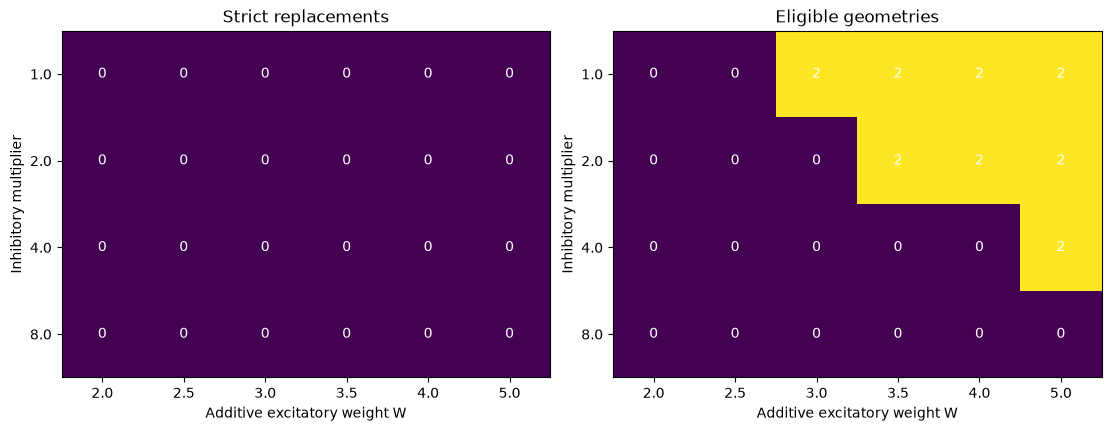

In [4]:
development = ("vertical", "horizontal")
held_out = ("diagonal", "L-shaped", "stepped")
weights = (2., 2.5, 3., 3.5, 4., 5.)
inhibition_scales = (1., 2., 4., 8.)

search = []
for additive_gain in tqdm(weights, desc="Additive recurrence gain"):
    for inhibitory_multiplier in inhibition_scales:
        settings = dict(mode="additive", weight=additive_gain, refractory_ms=1.,
                        inhibition_scale=inhibitory_multiplier, support=reference["support"])
        table = evaluate_geometries(settings, development)
        search.append(dict(weight=additive_gain, inhibition_scale=inhibitory_multiplier,
                           **totals(table)))
search_table = pd.DataFrame(search)
search_table = search_table.sort_values(
    ["eligible", "successes", "new_persistent", "old_silent", "off_target"],
    ascending=[False, False, False, False, True]).reset_index(drop=True)
display(search_table)

best = search_table.iloc[0]
candidate = dict(mode="additive", weight=float(best.weight), refractory_ms=1.,
                 inhibition_scale=float(best.inhibition_scale), support=reference["support"])
print("Development-set candidate:", candidate)
print("Development-set reference:", totals(reference_results.set_index("geometry").loc[list(development)].reset_index()))
print("Development-set candidate:", totals(evaluate_geometries(candidate, development)))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), constrained_layout=True)
for ax, metric, title in zip(axes, ["successes", "eligible"],
                             ["Strict replacements", "Eligible geometries"]):
    image = search_table.pivot(index="inhibition_scale", columns="weight", values=metric)
    plot = ax.imshow(image, vmin=0, vmax=len(development), cmap="viridis", aspect="auto")
    ax.set(xticks=range(len(image.columns)), xticklabels=image.columns,
           yticks=range(len(image.index)), yticklabels=image.index,
           xlabel="Additive excitatory weight W", ylabel="Inhibitory multiplier",
           title=title)
    for y in range(len(image.index)):
        for x in range(len(image.columns)):
            ax.text(x, y, str(int(image.iloc[y, x])), ha="center", va="center", color="white")
plt.show()

## 5. Full five-geometry validation, with no further tuning

The chosen candidate is now fixed. Test **all five** geometries with the same isolated controls, windows, and strict success definition as the reference. The held-out subset is reported separately so that a good development score is not mistaken for generalization.

We show the *number of old pixels silenced and new pixels retained*, not only a pass/fail label. Every model uses the same 9×9 spatial graph, external events, and simulation resolution. This comparison determines whether the additive model is competitive on the original task, not whether it uses fewer or more spikes overall.

,geometry,old_control_ref,new_control_ref,eligible_ref,old_silent_ref,new_persistent_ref,off_target_ref,success_ref,old_control_add,new_control_add,eligible_add,old_silent_add,new_persistent_add,off_target_add,success_add
0,vertical,5,5,True,5,5,0,True,5,5,True,0,5,0,False
1,horizontal,5,5,True,5,5,0,True,5,5,True,0,5,0,False
2,diagonal,5,5,True,4,5,0,False,5,5,True,0,5,0,False
3,L-shaped,5,5,True,5,4,0,False,5,5,True,0,5,0,False
4,stepped,5,5,True,5,5,0,True,5,5,True,0,5,0,False


Reference: {'eligible': 5, 'successes': 3, 'old_silent': 4.8, 'new_persistent': 4.8, 'off_target': 0}
Candidate: {'eligible': 5, 'successes': 0, 'old_silent': 0.0, 'new_persistent': 5.0, 'off_target': 0}
Held-out reference: {'eligible': 3, 'successes': 1, 'old_silent': 4.666666666666667, 'new_persistent': 4.666666666666667, 'off_target': 0}
Held-out candidate: {'eligible': 3, 'successes': 0, 'old_silent': 0.0, 'new_persistent': 5.0, 'off_target': 0}


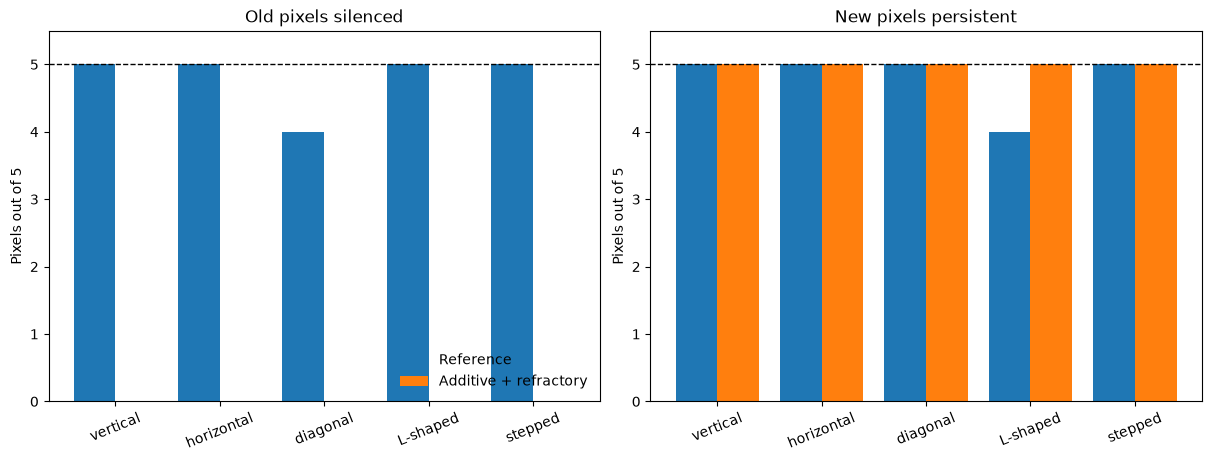

In [5]:
candidate_results = evaluate_geometries(candidate)
comparison = reference_results.merge(candidate_results, on="geometry", suffixes=("_ref", "_add"))
display(comparison)
print("Reference:", totals(reference_results))
print("Candidate:", totals(candidate_results))
print("Held-out reference:", totals(reference_results.set_index("geometry").loc[list(held_out)].reset_index()))
print("Held-out candidate:", totals(candidate_results.set_index("geometry").loc[list(held_out)].reset_index()))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
xx = np.arange(len(shapes))
for ax, field, title in zip(axes,
                            ("old_silent", "new_persistent"),
                            ("Old pixels silenced", "New pixels persistent")):
    ax.bar(xx - 0.2, comparison[f"{field}_ref"], width=0.4, label="Reference")
    ax.bar(xx + 0.2, comparison[f"{field}_add"], width=0.4, label="Additive + refractory")
    ax.axhline(5, color="black", ls="--", lw=1)
    ax.set(xticks=xx, xticklabels=list(shapes), ylim=(0, 5.5),
           title=title, ylabel="Pixels out of 5")
    ax.tick_params(axis="x", labelrotation=22)
axes[0].legend(loc="lower right", frameon=False)
plt.show()

## 6. Reproduce Notebook 19's 16 timing challenges

For the vertical geometry, vary the second input onset across **20, 40, 60, 80 ms** and the per-pixel event delay across **0, 0.25, 0.5, 1 ms**. This is the exact timing grid used in Notebook 19.

For the original Notebook 20 reference, the windows at 90–120 ms assess late persistence. For the fading reference, those windows are deliberately earlier; late second-stimulus onsets overlap or exceed the scoring window. **Such rows cannot be interpreted as replacement tests.** We therefore restrict fading-mode timing checks to the two onsets for which the second stimulus precedes the evaluation windows (20 and 40 ms); for 40 ms, the first scoring window overlaps input and only the later window is meaningful. A separate stimulus-relative timing test would be needed for the full 16-onset grid with fading.

Timing challenges: Additive: 100%|██████████| 1/1 [00:02<00:00,  2.92s/it]


,model,second_start_ms,stagger_ms,geometry,old_control,new_control,eligible,old_silent,new_persistent,off_target,success
0,Reference,20.0,0.00,vertical,5,5,True,5,5,0,True
1,Reference,20.0,0.25,vertical,5,5,True,5,5,0,True
2,Reference,20.0,0.50,vertical,5,5,True,5,5,0,True
3,Reference,20.0,1.00,vertical,5,5,True,5,5,0,True
4,Additive,20.0,0.00,vertical,5,5,True,0,5,0,False
5,Additive,20.0,0.25,vertical,5,5,True,0,5,0,False
6,Additive,20.0,0.50,vertical,5,5,True,0,5,0,False
7,Additive,20.0,1.00,vertical,5,5,True,0,5,0,False


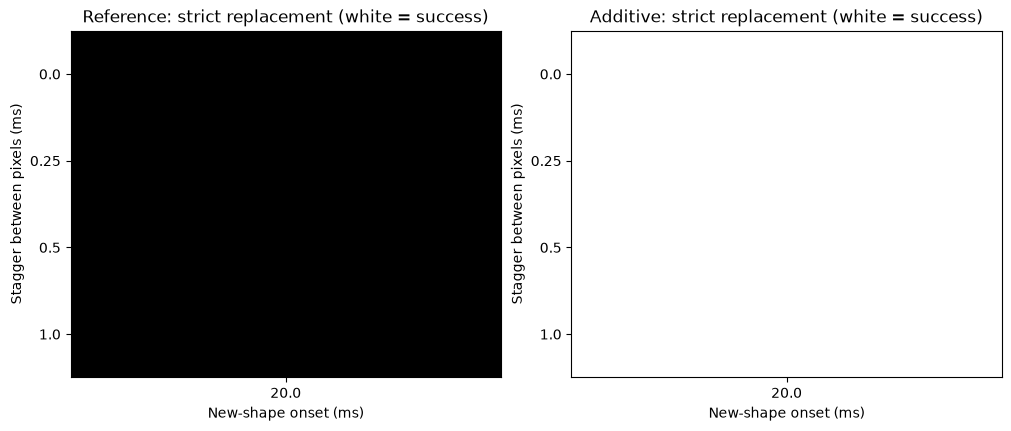

In [6]:
onsets = (20., 40., 60., 80.) if target == "original" else (20.,)
row_delays = (0., 0.25, 0.5, 1.)
timing_rows = []
for name, settings in (("Reference", reference), ("Additive", candidate)):
    for onset in tqdm(onsets, desc=f"Timing challenges: {name}"):
        for stagger in row_delays:
            row = evaluate_one("vertical", settings,
                               second_start=onset, row_delay=stagger)
            timing_rows.append(dict(model=name, second_start_ms=onset,
                                    stagger_ms=stagger, **row))
timing_table = pd.DataFrame(timing_rows)
display(timing_table)

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), constrained_layout=True)
for ax, (name, data) in zip(axes, timing_table.groupby("model", sort=False)):
    pivot = data.pivot(index="stagger_ms", columns="second_start_ms", values="success")
    ax.imshow(pivot.to_numpy(dtype=float), cmap="Greys", vmin=0, vmax=1, aspect="auto")
    ax.set(xticks=range(len(pivot.columns)), xticklabels=pivot.columns,
           yticks=range(len(pivot.index)), yticklabels=pivot.index,
           xlabel="New-shape onset (ms)", ylabel="Stagger between pixels (ms)",
           title=f"{name}: strict replacement (white = success)")
plt.show()

## 7. Firing rates and fading must also match

We stimulate a single central pixel at **2, 4, and 6 ms**, then supply **no further input**. We measure the last recurrent spike, interspike intervals, and post-stimulus firing in 5 ms bins. These are calculated **directly from spike timestamps**, not from a rendered video.

The fading reference is expected to become silent eventually; the original Notebook 20 model is *not required* to fade, because fading was added later. The candidate cannot be considered equivalent merely because its last-spike time matches: it must also satisfy the geometry and timing tests, with acceptable firing rates.

Reference: total spikes=54, last spike=89.20 ms, min ISI=0.250 ms
Additive: total spikes=72, last spike=85.70 ms, min ISI=1.000 ms


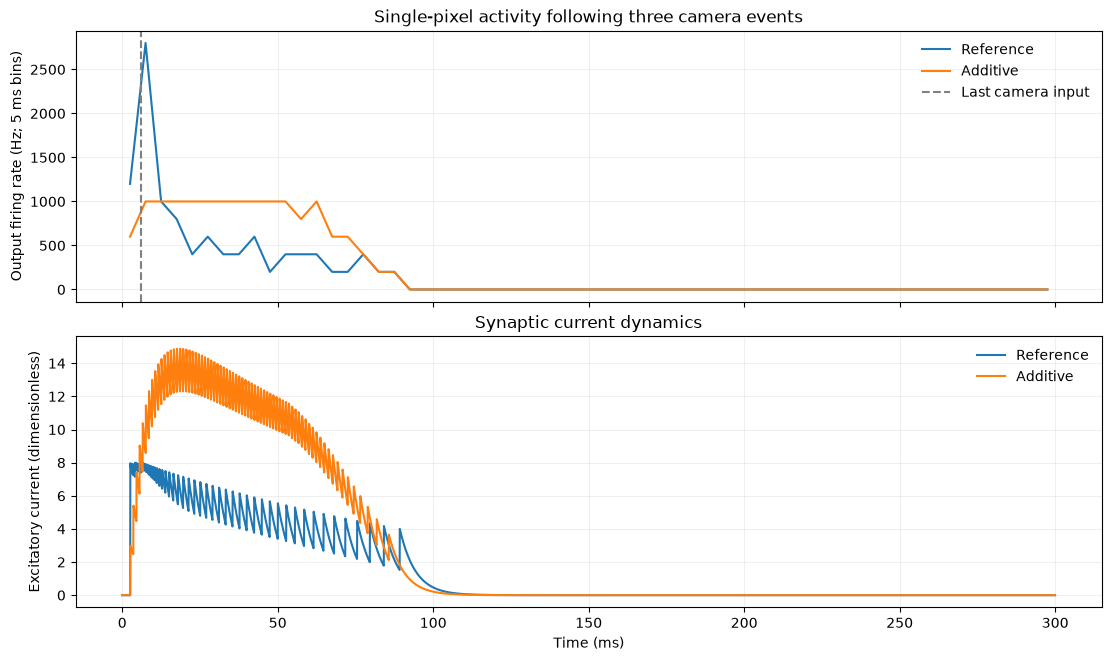

In [7]:
center = int(pixels([(4, 4)])[0])
solo = [(np.array([center]), old_pulses, 0.)]
traces = {}
fig, axes = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True, constrained_layout=True)
for name, settings in (("Reference", reference), ("Additive", candidate)):
    result = simulate(solo, **settings, duration_ms=300., trace_pixel=center)
    traces[name] = result
    times = result["t"]
    isis = np.diff(times)
    last = float(times[-1]) if len(times) else np.nan
    print(f"{name}: total spikes={len(times)}, last spike={last:.2f} ms, "
          f"min ISI={np.min(isis) if len(isis) else np.nan:.3f} ms")
    counts, _ = np.histogram(times, bins=np.arange(0, 305, 5))
    axes[0].plot(np.arange(len(counts))*5 + 2.5, counts/0.005, label=name)
    axes[1].plot(result["trace_t"], result["Iexc"], label=name)
axes[0].axvline(6., ls="--", color="grey", label="Last camera input")
axes[0].set(ylabel="Output firing rate (Hz; 5 ms bins)",
            title="Single-pixel activity following three camera events")
axes[1].set(xlabel="Time (ms)", ylabel="Excitatory current (dimensionless)",
            title="Synaptic current dynamics")
for ax in axes:
    ax.grid(alpha=0.2)
    ax.legend(frameon=False)
plt.show()

## 8. Check timestep sensitivity and make the calibration decision

Repeat the full geometry comparison for \(\Delta t=0.1,0.05,0.025\) ms on **both** models. The experiment is accepted only if the candidate matches the reference's strict geometry count, retains all five isolated controls, avoids off-target firing, and its classification remains stable across the tested resolutions.

We also require it to reproduce the **held-out** geometries rather than merely the tuned vertical and horizontal edges. For the fading version, the isolated-neuron firing duration is an additional explicit criterion; report it rather than inventing an arbitrary acceptance tolerance.

**If no candidate meets these requirements, the honest outcome is that additive + refractory remains uncalibrated.** Do not adopt the chosen parameters just because they ranked highest in the development grid. STD is intentionally excluded from this notebook; it will be a separate mechanistic replacement of sensory support after a functioning additive baseline is established.

In [8]:
refinement = []
for resolution in tqdm((0.1, 0.05, 0.025), desc="Time-step comparison"):
    for name, settings in (("Reference", reference), ("Additive", candidate)):
        result = evaluate_geometries(settings, dt=resolution)
        refinement.append(dict(model=name, dt_ms=resolution, **totals(result)))
refinement_table = pd.DataFrame(refinement)
display(refinement_table)

ref_score = totals(reference_results)
cand_score = totals(candidate_results)
geometry_match = (cand_score["eligible"] == 5 and
                  cand_score["successes"] >= ref_score["successes"] and
                  cand_score["off_target"] == 0)
heldout_passes = (candidate_results.set_index("geometry")
                  .loc[list(held_out), "success"].sum())
print("Matches the reference on strict five-geometry count and controls:", geometry_match)
print(f"Held-out successes: {heldout_passes}/{len(held_out)}")
print("Classification by timestep:")
display(refinement_table.pivot(index="dt_ms", columns="model", values="successes"))
print("Interpret with rate and fading curves before accepting any parameter set.")

Time-step comparison: 100%|██████████| 3/3 [00:24<00:00,  8.06s/it]


,model,dt_ms,eligible,successes,old_silent,new_persistent,off_target
0,Reference,0.100,5,3,4.8,4.8,0
1,Additive,0.100,5,0,0.0,5.0,0
2,Reference,0.050,5,3,4.8,4.8,0
3,Additive,0.050,5,0,0.0,5.0,0
4,Reference,0.025,5,3,4.8,4.8,0
5,Additive,0.025,5,0,0.0,5.0,0


Matches the reference on strict five-geometry count and controls: False
Held-out successes: 0/3
Classification by timestep:


model,Additive,Reference
dt_ms,,
0.025,0,3
0.050,0,3
0.100,0,3


Interpret with rate and fading curves before accepting any parameter set.
